# Исследовательский ноутбук прогнозированиz депозитов населения Беларуси
Помогают ли данные о новых депозитных договорах точнее прогнозировать остатки на счетах населения? Проверим это на статистике НБРБ: сравним простые прогнозы с Ridge, затем добавим показатели новых договоров и регуляторных условий. Рублёвые и валютные депозиты рассмотрим отдельно.
Есть важная оговорка: новый договор — не обязательно новые деньги. В статистику входят и продления вкладов.
Используем остатки за декабрь 2014 — август 2026 года, новые договоры — с января 2020 года. Этот период уже изучался при разработке моделей; здесь мы воспроизводим расчёты. Независимая проверка потребует новых данных.

In [1]:
from pathlib import Path
import pandas as pd

In [2]:
file_path = Path("data/broadmoney_ru.xlsx")
print("Файл найден:", file_path.exists())
excel_file = pd.ExcelFile(file_path)
excel_file.sheet_names

Файл найден: True


['2015',
 '2016',
 '2017',
 '2018',
 '2019',
 '2020',
 '2021',
 '2022',
 '2023',
 '2024',
 '2025',
 '2026']

In [3]:
def read_stock_year(excel_file, year):
    raw = pd.read_excel(excel_file, sheet_name=str(year), header=None)

    stocks = raw.iloc[[6, 10, 29, 32], 1:].T.copy()
    stocks.columns = [
        "byn_transfer",
        "byn_other",
        "fx_transfer_usd",
        "fx_other_usd",
    ]
    stocks = stocks.apply(pd.to_numeric, errors="raise")

    dates = pd.to_datetime(raw.iloc[3, 1:].values)
    stocks.index = dates.to_period("M") - 1
    stocks.index.name = "month"

    stocks["byn_stock_mln"] = (
        stocks["byn_transfer"] + stocks["byn_other"]
    )
    stocks["fx_stock_usd_mln"] = (
        stocks["fx_transfer_usd"] + stocks["fx_other_usd"]
    )

    return stocks

In [4]:
stocks_2016 = read_stock_year(excel_file, 2016)
stocks_2016.head()

,byn_transfer,byn_other,fx_transfer_usd,fx_other_usd,byn_stock_mln,fx_stock_usd_mln
month,,,,,,
2015-12,1405.9848,2614.4611,521.315,7691.459,4020.4459,8212.774
2016-01,1288.0616,2465.5978,419.011,7665.671,3753.6594,8084.682
2016-02,1235.0413,2428.7039,391.668,7549.098,3663.7452,7940.766
2016-03,1179.5471,2471.2406,376.209,7538.571,3650.7877,7914.780
2016-04,1349.7180,2494.9795,388.624,7445.861,3844.6975,7834.485


In [5]:
year_tables = []

for year in range(2015, 2027):
    year_stocks = read_stock_year(excel_file, year)
    year_tables.append(year_stocks)

stocks = pd.concat(year_tables).sort_index()

In [6]:
print("Размер:", stocks.shape)
print("Первый месяц:", stocks.index.min())
print("Последний месяц:", stocks.index.max())
print("Повторяющихся месяцев:", stocks.index.duplicated().sum())
print("Пропуски:")
print(stocks.isna().sum())

display(stocks.tail())

Размер: (141, 6)
Первый месяц: 2014-12
Последний месяц: 2026-08
Повторяющихся месяцев: 0
Пропуски:
byn_transfer        0
byn_other           0
fx_transfer_usd     0
fx_other_usd        0
byn_stock_mln       0
fx_stock_usd_mln    0
dtype: int64


,byn_transfer,byn_other,fx_transfer_usd,fx_other_usd,byn_stock_mln,fx_stock_usd_mln
month,,,,,,
2026-04,10932.757000,17023.781000,2673.642933,2398.987956,27956.538000,5072.630889
2026-05,11434.217000,17459.395000,2675.105812,2411.705682,28893.612000,5086.811494
2026-06,11768.758305,17862.671467,2656.852577,2360.831381,29631.429772,5017.683958
2026-07,12224.331068,18375.561653,2615.448830,2355.663044,30599.892721,4971.111873
2026-08,11885.148445,18939.671896,2599.715133,2314.293823,30824.820341,4914.008956


In [7]:
expected_months = pd.period_range(
    start="2014-12",
    end="2026-08",
    freq="M",
)

missing_months = expected_months.difference(stocks.index)
extra_months = stocks.index.difference(expected_months)

print("Отсутствующие месяцы:", missing_months)
print("Лишние месяцы:", extra_months)

assert stocks.index.is_unique
assert stocks.index.equals(expected_months)
assert stocks.notna().all().all()


Отсутствующие месяцы: PeriodIndex([], dtype='period[M]')
Лишние месяцы: PeriodIndex([], dtype='period[M]')


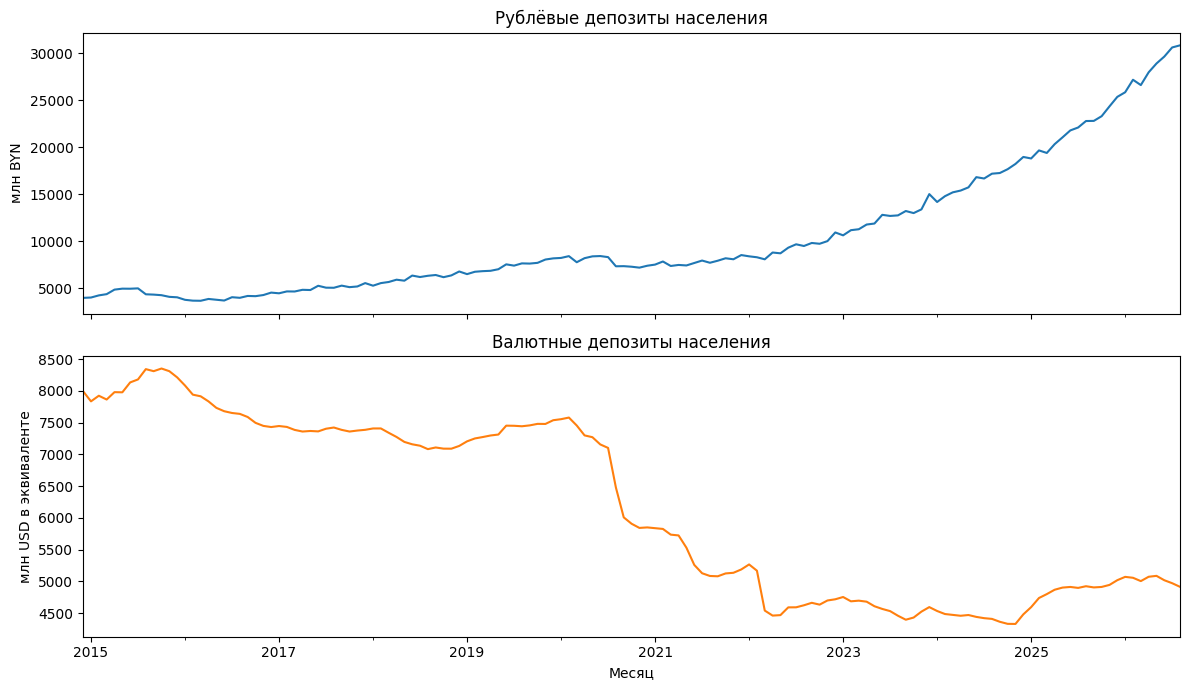

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

stocks["byn_stock_mln"].plot(ax=axes[0], color="tab:blue")
axes[0].set_title("Рублёвые депозиты населения")
axes[0].set_ylabel("млн BYN")

stocks["fx_stock_usd_mln"].plot(ax=axes[1], color="tab:orange")
axes[1].set_title("Валютные депозиты населения")
axes[1].set_ylabel("млн USD в эквиваленте")
axes[1].set_xlabel("Месяц")

plt.tight_layout()
plt.show()

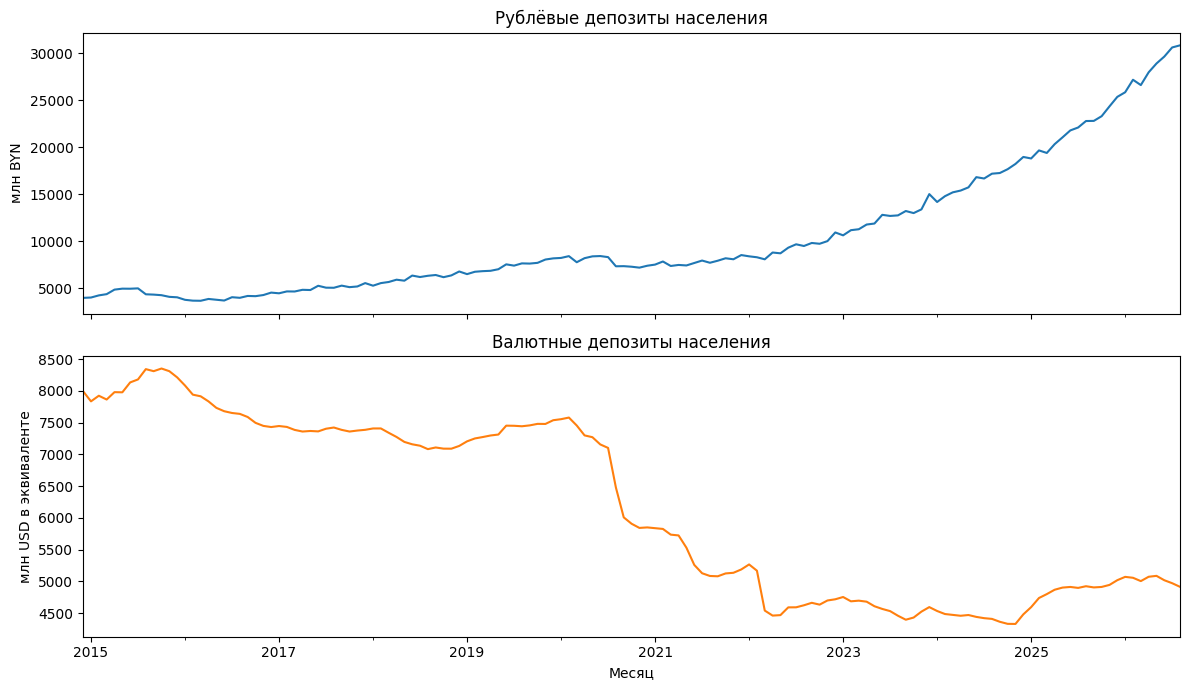

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

stocks["byn_stock_mln"].plot(ax=axes[0], color="tab:blue")
axes[0].set_title("Рублёвые депозиты населения")
axes[0].set_ylabel("млн BYN")

stocks["fx_stock_usd_mln"].plot(ax=axes[1], color="tab:orange")
axes[1].set_title("Валютные депозиты населения")
axes[1].set_ylabel("млн USD в эквиваленте")
axes[1].set_xlabel("Месяц")

plt.tight_layout()
plt.show()

         byn_stock_mln  fx_stock_usd_mln
month                                   
2014-12            NaN               NaN
2015-01       34.93555          -158.122
2015-02      227.62483            88.506
2015-03      132.27856           -59.733
2015-04      480.82123           116.278


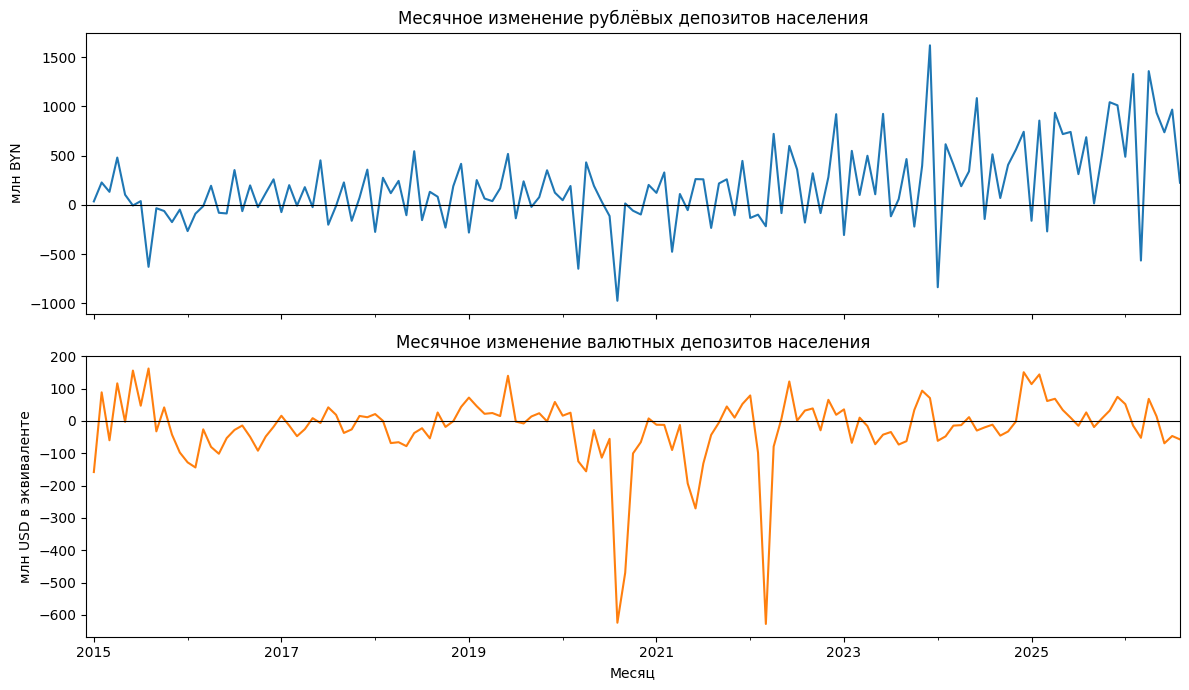

In [10]:
stock_changes = stocks[["byn_stock_mln", "fx_stock_usd_mln"]].diff()

print(stock_changes.head())

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

stock_changes["byn_stock_mln"].plot(ax=axes[0], color="tab:blue")
axes[0].set_title("Месячное изменение рублёвых депозитов населения")
axes[0].set_ylabel("млн BYN")
axes[0].axhline(0, color="black", linewidth=0.8)

stock_changes["fx_stock_usd_mln"].plot(ax=axes[1], color="tab:orange")
axes[1].set_title("Месячное изменение валютных депозитов населения")
axes[1].set_ylabel("млн USD в эквиваленте")
axes[1].set_xlabel("Месяц")
axes[1].axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()


In [11]:
stock_levels = stocks[["byn_stock_mln", "fx_stock_usd_mln"]].copy()

naive_predictions = stock_levels.shift(2)

comparison = pd.DataFrame({
    "actual_byn": stock_levels["byn_stock_mln"],
    "naive_byn": naive_predictions["byn_stock_mln"],
    "actual_fx": stock_levels["fx_stock_usd_mln"],
    "naive_fx": naive_predictions["fx_stock_usd_mln"],
})

comparison.tail(6)

,actual_byn,naive_byn,actual_fx,naive_fx
month,,,,
2026-03,26597.101000,25832.827000,5004.281551,5070.900126
2026-04,27956.538000,27163.394000,5072.630889,5056.487046
2026-05,28893.612000,26597.101000,5086.811494,5004.281551
2026-06,29631.429772,27956.538000,5017.683958,5072.630889
2026-07,30599.892721,28893.612000,4971.111873,5086.811494
2026-08,30824.820341,29631.429772,4914.008956,5017.683958


## Наивный подход

Базовой предсказательной моделью будем считать, что в следующем месяце количество депозитов будет как в предыдущем. Рассчитаем среднюю абсолютную ошибку для такой прогнозной модели.

In [13]:
evaluation = comparison.loc["2025-09":"2026-08"].copy()
evaluation["err_byn"] = evaluation["actual_byn"] - evaluation["naive_byn"]
evaluation["err_fx"] = evaluation["actual_fx"] - evaluation["naive_fx"]

naive_mae_byn = evaluation["err_byn"].abs().mean()
naive_mae_fx = evaluation["err_fx"].abs().mean()

print(f"MAE BYN: {naive_mae_byn:.3f} млн BYN")
print(f"MAE FX: {naive_mae_fx:.3f} млн USD в эквиваленте")


MAE BYN: 1380.581 млн BYN
MAE FX: 64.077 млн USD в эквиваленте


## Прогноз с продолжением тренда Drift12

Предположим, что остатки депозитов будут меняться с тем же средним темпом, что и за последние 12 месяцев. Продолжим этот тренд на два месяца от последнего доступного значения и рассчитаем среднюю абсолютную ошибку прогноза.

In [18]:
components = stocks[[
    "byn_transfer",
    "byn_other",
    "fx_transfer_usd",
    "fx_other_usd",
]]

last_available = components.shift(2)
year_earlier = components.shift(14)

growth_factor = (last_available / year_earlier) ** (2 / 12)

component_predictions = last_available * growth_factor

drift_predictions = pd.DataFrame({
    "byn_stock_mln": (
        component_predictions["byn_transfer"]
        + component_predictions["byn_other"]
    ),
    "fx_stock_usd_mln": (
        component_predictions["fx_transfer_usd"]
        + component_predictions["fx_other_usd"]
    ),
})

In [20]:
actual = stock_levels.loc["2025-09":"2026-08"]
predicted = drift_predictions.loc["2025-09":"2026-08"]

assert actual.index.equals(predicted.index)
assert len(predicted) == 12
assert predicted.notna().all().all()

drift_mae = (actual - predicted).abs().mean()

baseline_metrics = pd.DataFrame({
    "Naive": [naive_mae_byn, naive_mae_fx],
    "Drift12": [
        drift_mae["byn_stock_mln"],
        drift_mae["fx_stock_usd_mln"],
    ],
}, index=["BYN, млн BYN", "FX, млн USD в эквиваленте"])

display(baseline_metrics.round(3))

,Naive,Drift12
"BYN, млн BYN",1380.581,505.443
"FX, млн USD в эквиваленте",64.077,82.009


In [17]:
print(baseline_metrics.to_string())

                                 Naive     Drift12
BYN, млн BYN               1380.581422  538.837213
FX, млн USD в эквиваленте    64.076837   74.496718
